# Análise Exploratória: Preços de Combustíveis (ANP, 2023–2025)

Este notebook é a etapa **Python/Pandas** do pipeline. Ele tem duas partes:

| Parte | Lê de | Objetivo |
|---|---|---|
| **1. Qualidade** | `stg.precos_bruto` (cópia fiel dos CSVs) | Encontrar problemas no dado bruto. **Cada achado vira uma regra no Pentaho** (`trf_03_tratamento`). |
| **2. Análise** | `dw` / `mart` (modelo estrela já tratado) | Padrões, distribuições, outliers e as métricas que vão para o dashboard, com os valores de referência para conferir o Power BI. |

Python **não corrige dado**: toda regra de limpeza mora no ETL. Aqui a gente investiga, justifica e valida.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import sqlalchemy as sa
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from dotenv import dotenv_values

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = dotenv_values(ROOT / ".env")
engine = sa.create_engine(
    f"postgresql+psycopg2://bi_reader:{cfg['BI_PASSWORD']}@{cfg.get('DW_HOST', 'localhost')}:"
    f"{cfg['POSTGRES_PORT']}/{cfg['POSTGRES_DB']}"
)
sql = lambda q: pd.read_sql(q, engine)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

# Paleta (mesma do tema do Power BI): cor só onde há informação, resto em cinza
AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
CINZA, TINTA, TINTA_2 = "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": CINZA, "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.grid": True, "grid.color": "#ecebe7",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})
brl = mtick.FuncFormatter(lambda v, _: f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))

---
# Parte 1: Qualidade do dado bruto (`stg.precos_bruto`)

A staging é texto puro, exatamente como veio dos CSVs. Carregamos as colunas relevantes para a análise.

In [2]:
bruto = sql("""
    SELECT arquivo_origem, regiao_sigla, estado_sigla, municipio, revenda, cnpj_revenda,
           produto, data_coleta, valor_venda, valor_compra, unidade_medida, bandeira
    FROM stg.precos_bruto
""")
print(f"{len(bruto):,} linhas x {bruto.shape[1]} colunas")
bruto.head()

2,616,267 linhas x 12 colunas


,arquivo_origem,regiao_sigla,estado_sigla,municipio,revenda,cnpj_revenda,produto,data_coleta,valor_venda,valor_compra,unidade_medida,bandeira
0,ca-2023-01.csv,SE,SP,SOROCABA,COMPETRO COMERCIO E DISTRIBUICAO DE DERIVADOS ...,00.003.188/0001-21,ETANOL,03/01/2023,"3,39",None,R$ / litro,BRANCA
1,ca-2023-01.csv,SE,SP,SOROCABA,COMPETRO COMERCIO E DISTRIBUICAO DE DERIVADOS ...,00.003.188/0001-21,DIESEL S10,03/01/2023,"6,21",None,R$ / litro,BRANCA
2,ca-2023-01.csv,SE,SP,SOROCABA,COMPETRO COMERCIO E DISTRIBUICAO DE DERIVADOS ...,00.003.188/0001-21,GASOLINA,03/01/2023,"4,39",None,R$ / litro,BRANCA
3,ca-2023-01.csv,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,ETANOL,02/01/2023,"3,89",None,R$ / litro,VIBRA ENERGIA
4,ca-2023-01.csv,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,DIESEL,02/01/2023,"6,49",None,R$ / litro,VIBRA ENERGIA


### 1.1 Volume: a staging bate com os arquivos?

In [3]:
linhas_csv = {f.name: sum(1 for _ in open(f, encoding="utf-8-sig")) - 1
              for f in sorted((ROOT / "data/raw").glob("ca-*.csv"))}
vol = (bruto.groupby("arquivo_origem").size().rename("linhas_staging").to_frame()
       .assign(linhas_csv=pd.Series(linhas_csv)))
vol["confere"] = vol.linhas_staging == vol.linhas_csv
vol.loc["TOTAL"] = [vol.linhas_staging.sum(), vol.linhas_csv.sum(), vol.confere.all()]
vol

,linhas_staging,linhas_csv,confere
arquivo_origem,,,
ca-2023-01.csv,431576,431576,True
ca-2023-02.csv,472424,472424,True
ca-2024-01.csv,477154,477154,True
ca-2024-02.csv,421382,421382,True
ca-2025-01.csv,429523,429523,True
ca-2025-02.csv,384208,384208,True
TOTAL,2616267,2616267,True


### 1.2 Linhas vazias

In [4]:
vazia = bruto.drop(columns="arquivo_origem").isna().all(axis=1)
bruto[vazia].groupby("arquivo_origem").size().rename("linhas_vazias").to_frame()

,linhas_vazias
arquivo_origem,
ca-2025-01.csv,9114


> **Achado 1:** o arquivo `ca-2025-01.csv` traz **9.114 linhas só com separadores** (`;;;;`).
> **Regra no ETL:** step *Filter rows* "Descarta linhas vazias" (CNPJ e produto não nulos).

In [5]:
bruto = bruto[~vazia].copy()

### 1.3 Nulos por coluna

In [6]:
(bruto.isna().mean().mul(100).round(2).sort_values(ascending=False)
 .rename("% nulo").to_frame().query("`% nulo` > 0"))

,% nulo
valor_compra,100.000


> **Achado 2:** `valor_compra` é **100% nulo** no período inteiro. A ANP deixou de publicar o preço de compra.
> **Decisão:** a análise de margem do posto fica **fora do escopo**. A coluna fica na fato só como informação.

### 1.4 Formato do CNPJ muda entre arquivos

In [7]:
def formato_cnpj(s):
    if s.startswith(" "): return "máscara com espaço à esquerda"
    if "." in s: return "máscara sem espaço"
    return "só dígitos" if s.isdigit() else "outro"

pd.crosstab(bruto.arquivo_origem, bruto.cnpj_revenda.map(formato_cnpj))

cnpj_revenda,máscara com espaço à esquerda,só dígitos
arquivo_origem,,
ca-2023-01.csv,431576,0
ca-2023-02.csv,472424,0
ca-2024-01.csv,477154,0
ca-2024-02.csv,421382,0
ca-2025-01.csv,420409,0
ca-2025-02.csv,0,384208


> **Achado 3:** até 2025-01 o CNPJ vem como `" 00.003.188/0001-21"` (com espaço e máscara). Em 2025-02 vem `"04431113000100"`.
> Sem tratamento, **o mesmo posto viraria duas revendas diferentes** na dimensão.
> **Regra no ETL:** *String operations* com "digits only" no CNPJ (e no CEP).

In [8]:
cnpj_digitos = bruto.cnpj_revenda.str.replace(r"\D", "", regex=True)
print("Comprimentos após limpeza:", cnpj_digitos.str.len().value_counts().to_dict())
print(f"CNPJs distintos: brutos = {bruto.cnpj_revenda.nunique():,}  |  só dígitos = {cnpj_digitos.nunique():,}")

Comprimentos após limpeza: {14: 2607153}


CNPJs distintos: brutos = 20,960  |  só dígitos = 13,515


### 1.5 Unidade de medida

In [9]:
pd.crosstab(bruto.produto, bruto.unidade_medida)

unidade_medida,R$ / litro,R$ / m3,R$ / m³
produto,,,
DIESEL,294686,0,0
DIESEL S10,479270,0,0
ETANOL,572908,0,0
GASOLINA,677528,0,0
GASOLINA ADITIVADA,527087,0,0
GNV,0,8732,46942


> **Achado 4:** o GNV aparece como `R$ / m3` **e** `R$ / m³`, a mesma unidade escrita de dois jeitos.
> **Regra no ETL:** *Replace in string* `m3$ → m³`.

### 1.6 Bandeiras: sinônimos

In [10]:
top = bruto.bandeira.value_counts()
print(f"{top.size} bandeiras distintas. As 12 mais frequentes:")
top.head(12).to_frame("coletas")

58 bandeiras distintas. As 12 mais frequentes:


,coletas
bandeira,
BRANCA,884167
IPIRANGA,556398
VIBRA,452995
RAIZEN,382166
VIBRA ENERGIA,99128
ALESAT,47102
ALE,38882
SABBÁ,27486
ATEM' S,11623


In [11]:
suspeitas = ["VIBRA", "VIBRA ENERGIA", "ALE", "ALESAT"]
pd.crosstab(bruto.bandeira, bruto.arquivo_origem).loc[suspeitas]

arquivo_origem,ca-2023-01.csv,ca-2023-02.csv,ca-2024-01.csv,ca-2024-02.csv,ca-2025-01.csv,ca-2025-02.csv
bandeira,,,,,,
VIBRA,0,90054,98528,87213,92844,84356
VIBRA ENERGIA,91748,7380,0,0,0,0
ALE,0,0,4490,12756,11664,9972
ALESAT,16831,17446,12825,0,0,0


> **Achado 5:** a mesma distribuidora **muda de nome ao longo da série**: `VIBRA ENERGIA` (antiga BR) vira `VIBRA` em 2023-02,
> e `ALESAT` vira `ALE` em 2024-01. Sem unificação, uma bandeira "sumiria" do dashboard e outra "nasceria" no meio do período.
> **Regra no ETL:** *Value mapper* `VIBRA ENERGIA → VIBRA`, `ALESAT → ALE`.
> `RAIZEN MIME` foi mantida separada: é uma joint venture com operação própria.

> Mesmo com 3 × IQR, o Norte concentra a maior parte dos marcados (~3%). São postos isolados com preço muito acima da própria região.

### 1.7 Duplicatas no grão (CNPJ × produto × data)

In [12]:
grao = pd.DataFrame({"cnpj": cnpj_digitos, "produto": bruto.produto, "data": bruto.data_coleta})
dup = grao.duplicated(keep=False)
print(f"Linhas envolvidas em duplicidade: {dup.sum():,}  ->  removidas: {grao.duplicated().sum():,}")
bruto[dup].sort_values(["cnpj_revenda", "produto", "data_coleta"]).head(6)[
    ["arquivo_origem", "revenda", "produto", "data_coleta", "valor_venda"]]

Linhas envolvidas em duplicidade: 28  ->  removidas: 14


,arquivo_origem,revenda,produto,data_coleta,valor_venda
1328035,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA,10/06/2024,"5,48"
1328037,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA,10/06/2024,"5,65"
1338655,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA,12/06/2024,"5,48"
1338657,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA,12/06/2024,"5,65"
1328036,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA ADITIVADA,10/06/2024,"5,59"
1328038,ca-2024-01.csv,AUTO POSTO MANGUEIRA II LTDA,GASOLINA ADITIVADA,10/06/2024,"5,77"


> **Achado 6:** são poucas duplicatas, mas existem. O grão da fato exige unicidade.
> **Regra no ETL:** *Unique rows* em `trf_05_fato` (mantém a 1ª ocorrência). Além disso, um **índice único** no banco faz a carga falhar se alguma passar.

### 1.8 Preço: conversão, distribuição e outliers

In [13]:
bruto["preco"] = pd.to_numeric(bruto.valor_venda.str.replace(",", ".", regex=False), errors="coerce")
print("Não convertidos:", bruto.preco.isna().sum())
bruto.groupby("produto").preco.describe(percentiles=[.01, .25, .5, .75, .99])

Não convertidos: 0


,count,mean,std,min,1%,25%,50%,75%,99%,max
produto,,,,,,,,,,
DIESEL,"294,686.000",5.948,0.495,3.970,4.660,5.690,5.940,6.200,7.290,8.390
DIESEL S10,"479,270.000",6.024,0.497,4.190,4.690,5.790,5.990,6.290,7.290,9.290
ETANOL,"572,908.000",4.167,0.537,2.630,3.040,3.790,4.140,4.500,5.490,7.440
GASOLINA,"677,528.000",5.892,0.512,4.090,4.790,5.570,5.890,6.190,7.160,9.290
GASOLINA ADITIVADA,"527,087.000",6.082,0.522,3.470,4.940,5.750,6.090,6.390,7.370,9.790
GNV,"55,674.000",4.718,0.490,2.390,3.390,4.390,4.690,4.990,6.090,6.890


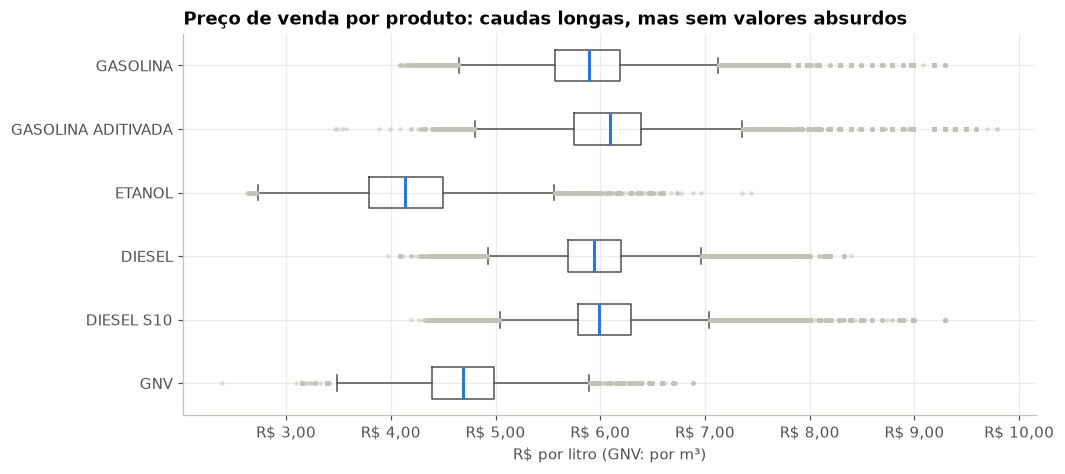

In [14]:
ordem = ["GASOLINA", "GASOLINA ADITIVADA", "ETANOL", "DIESEL", "DIESEL S10", "GNV"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([bruto.loc[bruto.produto == p, "preco"] for p in ordem], tick_labels=ordem, orientation="horizontal",
           widths=.5, flierprops=dict(marker="o", markersize=3, markerfacecolor=CINZA, markeredgecolor="none", alpha=.5),
           medianprops=dict(color=AZUL, linewidth=2), boxprops=dict(color=TINTA_2), whiskerprops=dict(color=TINTA_2),
           capprops=dict(color=TINTA_2))
ax.invert_yaxis(); ax.xaxis.set_major_formatter(brl)
ax.set_title("Preço de venda por produto: caudas longas, mas sem valores absurdos")
ax.set_xlabel("R$ por litro (GNV: por m³)")
plt.show()

O preço vem limpo da ANP: não aparece vírgula deslocada (ex.: 59,90 no lugar de 5,99) e o máximo é inferior a R$ 10.
Os pontos fora das caixas são, em boa parte, **preço real de regiões mais caras**. Por isso a escolha do multiplicador do IQR importa:

In [15]:
d = bruto.assign(mes=bruto.data_coleta.str[3:]).dropna(subset=["preco"])
g = d.groupby(["produto", "mes"]).preco
q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
iqr = q3 - q1
for k in (1.5, 3):
    d[f"outlier_{k}x"] = (d.preco < q1 - k * iqr) | (d.preco > q3 + k * iqr)

comp = d.groupby("regiao_sigla")[["outlier_1.5x", "outlier_3x"]].mean().mul(100)
comp.loc["BRASIL"] = d[["outlier_1.5x", "outlier_3x"]].mean().mul(100)
comp.round(2).rename(columns=lambda c: "% marcado " + c.split("_")[1])

,% marcado 1.5x,% marcado 3x
regiao_sigla,,
CO,1.210,0.140
N,13.640,3.020
NE,1.250,0.020
S,1.120,0.030
SE,1.720,0.490
BRASIL,2.280,0.460


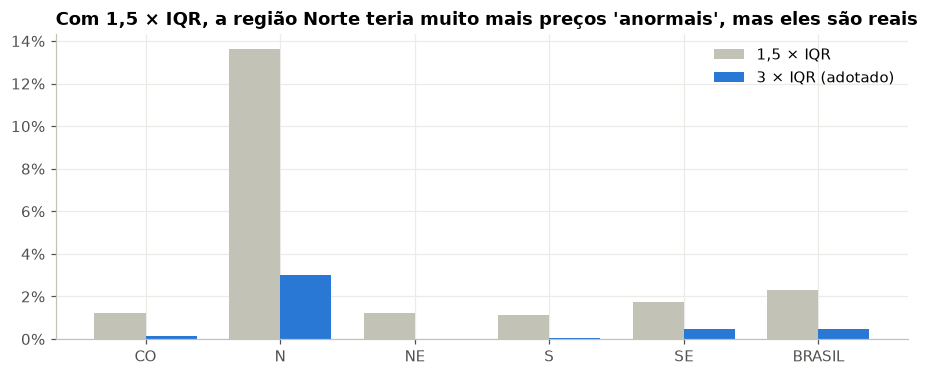

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(comp)); w = .38
ax.bar(x - w/2, comp["outlier_1.5x"], w, color=CINZA, label="1,5 × IQR")
ax.bar(x + w/2, comp["outlier_3x"], w, color=AZUL, label="3 × IQR (adotado)")
ax.set_xticks(x, comp.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Com 1,5 × IQR, a região Norte teria muito mais preços 'anormais', mas eles são reais")
ax.legend(loc="upper right"); plt.show()

> **Achado 7:** com 1,5 × IQR, as regiões mais caras teriam preço legítimo marcado como anormal.
> **Regra:** 3 × IQR por **produto × mês**, aplicada em SQL pelo job (`sql/04_outliers.sql`).
> O registro **não é apagado**: recebe `fl_outlier = 1`, e as medidas do dashboard o excluem.

### 1.9 Resumo: Achado → Regra no ETL

In [17]:
pd.DataFrame([
    (1, "9.114 linhas vazias em ca-2025-01.csv", "Filter rows 'Descarta linhas vazias'", "trf_03_tratamento"),
    (2, "valor_compra 100% nulo", "Mantido como informação; margem fora do escopo", "pentaho/README.md"),
    (3, "CNPJ com/sem máscara e espaço", "String operations: digits only", "trf_03_tratamento"),
    (4, "Unidade 'R$ / m3' x 'R$ / m³'", "Replace in string m3$ -> m³", "trf_03_tratamento"),
    (5, "Bandeiras sinônimas (VIBRA/VIBRA ENERGIA, ALE/ALESAT)", "Value mapper", "trf_03_tratamento"),
    (6, "Duplicatas no grão", "Unique rows + índice único", "trf_05_fato / 03_ddl_dw.sql"),
    (7, "Caudas de preço regionais", "Outlier 3×IQR por produto×mês, marcado e não apagado", "04_outliers.sql"),
    (8, "Preço com vírgula decimal / data dd/MM/yyyy", "Select values (metadata)", "trf_03_tratamento"),
], columns=["#", "Achado na EDA", "Regra aplicada", "Onde"]).set_index("#")

,Achado na EDA,Regra aplicada,Onde
#,,,
1,9.114 linhas vazias em ca-2025-01.csv,Filter rows 'Descarta linhas vazias',trf_03_tratamento
2,valor_compra 100% nulo,Mantido como informação; margem fora do escopo,pentaho/README.md
3,CNPJ com/sem máscara e espaço,String operations: digits only,trf_03_tratamento
4,Unidade 'R$ / m3' x 'R$ / m³',Replace in string m3$ -> m³,trf_03_tratamento
5,"Bandeiras sinônimas (VIBRA/VIBRA ENERGIA, ALE/...",Value mapper,trf_03_tratamento
6,Duplicatas no grão,Unique rows + índice único,trf_05_fato / 03_ddl_dw.sql
7,Caudas de preço regionais,"Outlier 3×IQR por produto×mês, marcado e não a...",04_outliers.sql
8,Preço com vírgula decimal / data dd/MM/yyyy,Select values (metadata),trf_03_tratamento


In [18]:
# Conferência: o que o ETL fez, segundo o log de validação do job
sql("SELECT verificacao, valor, ok FROM dw.log_carga "
    "WHERE dt_execucao = (SELECT MAX(dt_execucao) FROM dw.log_carga) ORDER BY id_log")

,verificacao,valor,ok
0,linhas_stg_bruto,2616267,True
1,linhas_vazias_descartadas,9114,True
2,linhas_stg_tratado,2607153,True
3,linhas_fato,2607139,True
4,duplicatas_removidas_no_grao,14,True
5,linhas_fato_com_chave_-1,0,True
6,outliers_marcados,11951,True
7,dias_faltando_dim_data,0,True
8,linhas_com_valor_compra,0,True


In [19]:
del bruto, d, grao, cnpj_digitos  # libera memória antes da parte 2

---
# Parte 2: Análise (modelo estrela tratado)

A partir daqui os dados já passaram pelo ETL. As medidas usam **apenas `fl_outlier = 0`**, igual ao DAX.

In [20]:
fato = sql("""
    SELECT d.data, d.ano, d.ano_mes, l.regiao_nome, l.uf_sigla, l.municipio,
           p.produto, p.grupo_produto, b.tipo_bandeira, f.sk_revenda, f.valor_venda
    FROM mart.vw_fato_preco f
    JOIN mart.vw_dim_data d       ON d.sk_data = f.sk_data
    JOIN mart.vw_dim_localidade l ON l.sk_localidade = f.sk_localidade
    JOIN mart.vw_dim_produto p    ON p.sk_produto = f.sk_produto
    JOIN mart.vw_dim_bandeira b   ON b.sk_bandeira = f.sk_bandeira
    WHERE f.fl_outlier = 0
""")
print(f"{len(fato):,} coletas válidas | {fato.sk_revenda.nunique():,} postos | "
      f"{len(fato[["uf_sigla", "municipio"]].drop_duplicates()):,} municípios | {fato.data.min()} a {fato.data.max()}")

2,595,188 coletas válidas | 13,513 postos | 462 municípios | 2023-01-02 a 2025-12-31


### 2.1 Preço médio anual por produto

In [21]:
anual = fato.pivot_table(index="produto", columns="ano", values="valor_venda", aggfunc="mean").reindex(ordem)
anual["var_2023_2025"] = anual[2025] / anual[2023] - 1
anual.style.format({2023: "R$ {:.3f}", 2024: "R$ {:.3f}", 2025: "R$ {:.3f}", "var_2023_2025": "{:+.1%}"})

ano,2023,2024,2025,var_2023_2025
produto,,,,
GASOLINA,R$ 5.525,R$ 5.921,R$ 6.230,+12.8%
GASOLINA ADITIVADA,R$ 5.706,R$ 6.108,R$ 6.426,+12.6%
ETANOL,R$ 4.003,R$ 4.068,R$ 4.458,+11.3%
DIESEL,R$ 5.752,R$ 5.958,R$ 6.145,+6.8%
DIESEL S10,R$ 5.852,R$ 6.019,R$ 6.188,+5.7%
GNV,R$ 4.643,R$ 4.761,R$ 4.734,+2.0%


### 2.2 Evolução mensal: gasolina, etanol e diesel S10

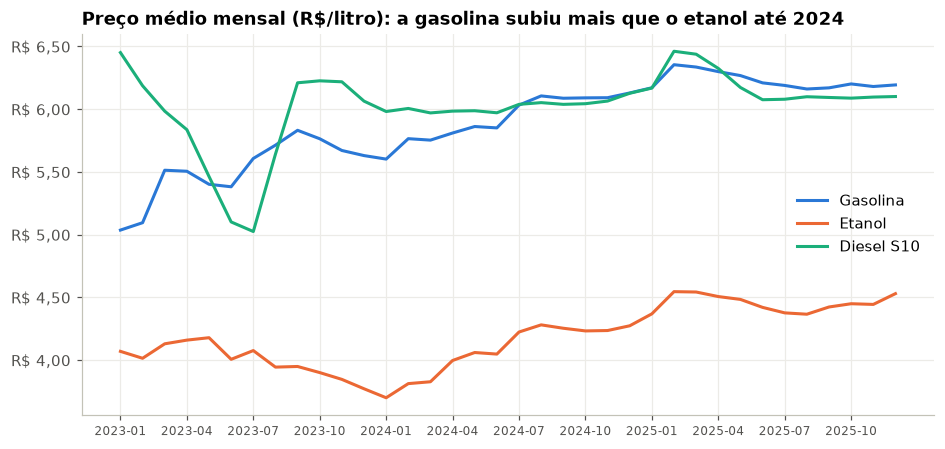

In [22]:
mensal = (fato[fato.produto.isin(["GASOLINA", "ETANOL", "DIESEL S10"])]
          .groupby(["ano_mes", "produto"]).valor_venda.mean().unstack())
fig, ax = plt.subplots()
for p, cor in [("GASOLINA", AZUL), ("ETANOL", LARANJA), ("DIESEL S10", VERDE_AGUA)]:
    ax.plot(mensal.index, mensal[p], color=cor, label=p.title())
ax.yaxis.set_major_formatter(brl)
ax.set_xticks(range(0, len(mensal), 3), mensal.index[::3], rotation=0, fontsize=8)
ax.set_title("Preço médio mensal (R$/litro): a gasolina subiu mais que o etanol até 2024")
ax.legend(loc="center right"); plt.show()

### 2.3 A métrica central: paridade etanol / gasolina

**Paridade = preço médio do etanol ÷ preço médio da gasolina comum.** Como o etanol rende cerca de 70% da gasolina por litro,
a regra de mercado é: **paridade ≤ 0,70 → etanol compensa**.

In [23]:
def paridade(df):
    e = df.loc[df.produto == "ETANOL", "valor_venda"].mean()
    g = df.loc[df.produto == "GASOLINA", "valor_venda"].mean()
    return e / g

par_ano = fato.groupby("ano").apply(paridade).rename("paridade_brasil").to_frame()
par_ano["etanol_compensa"] = par_ano.paridade_brasil <= .70
par_ano

,paridade_brasil,etanol_compensa
ano,,
2023,0.725,False
2024,0.687,True
2025,0.716,False


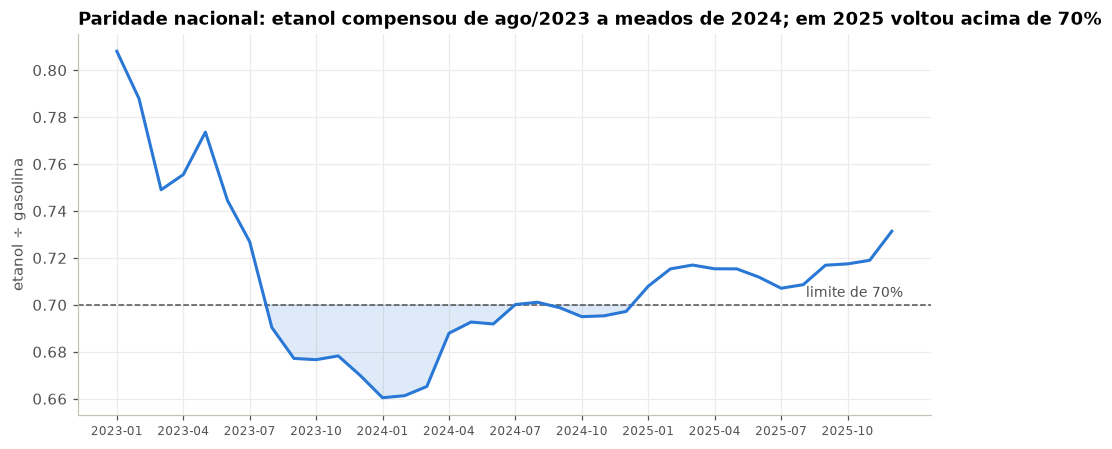

In [24]:
par_mes = fato.groupby("ano_mes").apply(paridade)
fig, ax = plt.subplots()
ax.axhline(.70, color=TINTA_2, linewidth=1, linestyle="--")
ax.text(len(par_mes) - .5, .702, "limite de 70%", ha="right", va="bottom", color=TINTA_2, fontsize=9)
ax.fill_between(range(len(par_mes)), par_mes.values, .70, where=par_mes.values <= .70,
                color=AZUL, alpha=.15, interpolate=True)
ax.plot(range(len(par_mes)), par_mes.values, color=AZUL)
ax.set_xticks(range(0, len(par_mes), 3), par_mes.index[::3], fontsize=8)
ax.set_title("Paridade nacional: etanol compensou de ago/2023 a dez/2024 (jul–ago/2024 no limite); em 2025 voltou acima de 70%")
ax.set_ylabel("etanol ÷ gasolina"); plt.show()

### 2.4 Onde o etanol compensa (2025, por UF)

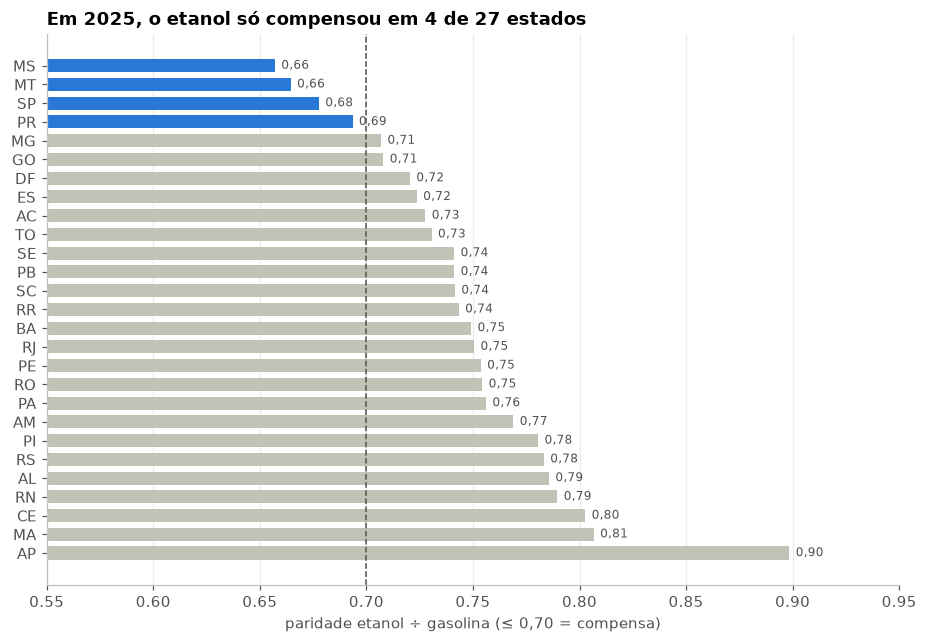

,paridade,compensa
uf_sigla,,
MS,0.657,True
MT,0.665,True
SP,0.678,True
PR,0.694,True


In [25]:
par_uf = (fato[fato.ano == 2025].groupby("uf_sigla").apply(paridade)
          .sort_values().rename("paridade").to_frame())
par_uf["compensa"] = par_uf.paridade <= .70
fig, ax = plt.subplots(figsize=(10, 6.5))
cores = [AZUL if c else CINZA for c in par_uf.compensa]
ax.barh(par_uf.index, par_uf.paridade, color=cores, height=.7)
ax.axvline(.70, color=TINTA_2, linewidth=1, linestyle="--")
ax.invert_yaxis(); ax.set_xlim(.55, .95); ax.grid(axis="y", visible=False)
for i, (uf, v) in enumerate(par_uf.paridade.items()):
    ax.text(v + .003, i, f"{v:.2f}".replace(".", ","), va="center", fontsize=8, color=TINTA_2)
ax.set_title(f"Em 2025, o etanol só compensou em {par_uf.compensa.sum()} de {len(par_uf)} estados")
ax.set_xlabel("paridade etanol ÷ gasolina (≤ 0,70 = compensa)"); plt.show()
par_uf[par_uf.compensa]

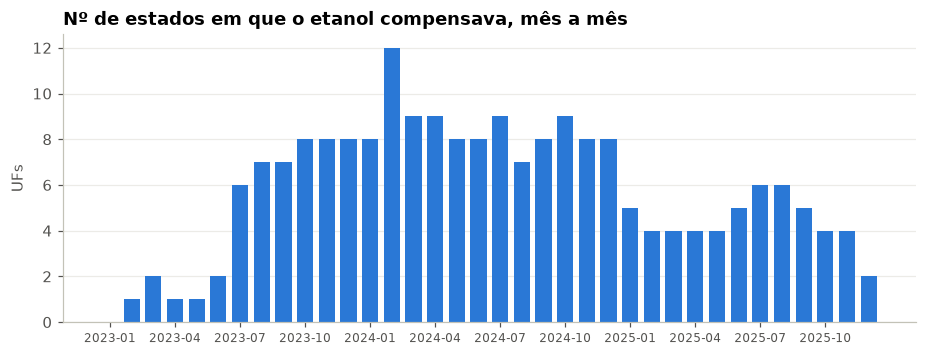

In [26]:
# Quantos estados por mês ficaram abaixo de 70%?
ufs_mes = sql("SELECT ano_mes, COUNT(*) FILTER (WHERE etanol_compensa) AS ufs FROM mart.vw_paridade_mensal_uf "
              "GROUP BY 1 ORDER BY 1").set_index("ano_mes").ufs
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(ufs_mes)), ufs_mes.values, color=AZUL, width=.75)
ax.set_xticks(range(0, len(ufs_mes), 3), ufs_mes.index[::3], fontsize=8)
ax.set_title("Nº de estados em que o etanol compensava, mês a mês"); ax.set_ylabel("UFs")
ax.grid(axis="x", visible=False); plt.show()

### 2.5 E nos municípios?

In [27]:
par_mun = (fato[fato.ano == 2025].groupby(["uf_sigla", "municipio"])
           .apply(lambda df: paridade(df) if {"ETANOL", "GASOLINA"} <= set(df.produto) else np.nan)
           .dropna())
print(f"Municípios com etanol e gasolina pesquisados em 2025: {par_mun.size}")
print(f"% em que o etanol compensou: {(par_mun <= .70).mean():.1%}")
(par_mun <= .70).groupby(level=0).mean().sort_values(ascending=False).head(8).map("{:.0%}".format).to_frame("% municípios")

Municípios com etanol e gasolina pesquisados em 2025: 416
% em que o etanol compensou: 33.9%


,% municípios
uf_sigla,
MT,100%
SP,89%
MS,80%
PR,54%
GO,50%
MG,30%
ES,10%
PA,9%


### 2.6 Bandeira branca é mais barata?

In [28]:
gas = fato[fato.produto == "GASOLINA"]
band = gas.pivot_table(index="regiao_nome", columns="tipo_bandeira", values="valor_venda", aggfunc="mean")
band["diferencial_R$"] = band["Bandeira branca"] - band["Distribuidora"]
band.loc["Brasil"] = [gas[gas.tipo_bandeira == t].valor_venda.mean() for t in ["Bandeira branca", "Distribuidora"]] + [np.nan]
band.loc["Brasil", "diferencial_R$"] = band.loc["Brasil", "Bandeira branca"] - band.loc["Brasil", "Distribuidora"]
band

tipo_bandeira,Bandeira branca,Distribuidora,diferencial_R$
regiao_nome,,,
Centro-Oeste,5.823,5.946,-0.123
Nordeste,5.965,5.989,-0.024
Norte,6.065,6.349,-0.284
Sudeste,5.597,5.842,-0.245
Sul,5.843,5.986,-0.143
Brasil,5.763,5.943,-0.180


Sim, mas a diferença é pequena: cerca de **R$ 0,18 por litro** de gasolina na média nacional. É um achado secundário, que pode entrar
como página de detalhe no dashboard.

### 2.7 Dispersão de preço por UF (coeficiente de variação, gasolina 2025)

In [29]:
cv = (fato[(fato.ano == 2025) & (fato.produto == "GASOLINA")].groupby("uf_sigla").valor_venda
      .agg(["mean", "std"]).assign(cv=lambda t: t["std"] / t["mean"]).sort_values("cv", ascending=False))
cv.head(5).style.format({"mean": "R$ {:.3f}", "std": "{:.3f}", "cv": "{:.1%}"})

,mean,std,cv
uf_sigla,,,
PA,R$ 6.401,0.448,7.0%
MA,R$ 6.129,0.421,6.9%
MS,R$ 6.207,0.424,6.8%
PE,R$ 6.330,0.361,5.7%
RN,R$ 6.331,0.350,5.5%


---
### 2.8 Valores de referência para conferir o Power BI

Regra de ouro: **os números do dashboard precisam bater com estes.** Com o filtro de ano = 2025:

In [30]:
f25 = fato[fato.ano == 2025]
ref = pd.Series({
    "Preço Médio gasolina (R$)": f25.loc[f25.produto == "GASOLINA", "valor_venda"].mean(),
    "Preço Médio etanol (R$)": f25.loc[f25.produto == "ETANOL", "valor_venda"].mean(),
    "Paridade Etanol/Gasolina": paridade(f25),
    "UFs onde etanol compensa": int(par_uf.compensa.sum()),
    "% Municípios onde etanol compensa": (par_mun <= .70).mean(),
    "Qtd Postos": f25.sk_revenda.nunique(),
    "Qtd Coletas (todos os produtos)": len(f25),
}).to_frame("valor_2025")
ref.round(4).to_csv(ROOT / "docs/kpis_referencia.csv", sep=";", decimal=",")
ref

,valor_2025
Preço Médio gasolina (R$),6.230
Preço Médio etanol (R$),4.458
Paridade Etanol/Gasolina,0.716
UFs onde etanol compensa,4.000
% Municípios onde etanol compensa,0.339
Qtd Postos,"8,699.000"
Qtd Coletas (todos os produtos),"799,859.000"


---
## Conclusões que vão para o dashboard

1. **Gancho:** entre 2023 e 2025 a gasolina subiu bem mais que o etanol (seção 2.1).
2. **Achado principal:** na média nacional, o etanol **compensava em 2024** (paridade abaixo de 0,70) e **deixou de compensar em 2025**.
   Em 2025 ele só valeu a pena em **4 estados (MS, MT, SP e PR)**, todos do cinturão produtor de cana do Centro-Sul.
   No Norte e no Nordeste, abastecer com etanol é quase sempre pior negócio.
3. **Recomendação ao público:** a regra dos 70% depende de onde você mora. Uma média nacional não serve para decidir no posto.
4. **Secundário:** postos de bandeira branca são em média ~R$ 0,18/l mais baratos na gasolina (até R$ 0,28 no Norte).

**Decisões de tratamento justificadas aqui:** filtro de linhas vazias, normalização do CNPJ, unificação de unidade e bandeiras,
deduplicação no grão e outlier por 3×IQR, marcado e não apagado. Todas estão implementadas no Pentaho, e não neste notebook.